# Analysis 1.A — Treasury curve conditions and movements

Inspect 2Y/10Y/30Y Treasury yields and compare exact endpoints. Yield levels are percent; spread levels and all changes are basis points. Start Jupyter from the repository root with `poetry run jupyter lab` after `poetry install`, using the Poetry Python kernel.

Execute **A → B → C → D** manually. After changing either DatePicker, rerun C to redraw the selected period and D to recalculate; each reads the widgets independently. Zoom, pan and the range slider inspect the history without changing selected analysis dates. No automatic callbacks are installed.

`download` retrieves and saves one self-contained CSV with comment-header provenance. The key order is explicit Python argument → `FRED_API_KEY` environment variable → root `.env`; without a key, the three known H.15 series use FRED's public CSV. `file` reads the selected CSV offline. Old JSON caches must be downloaded again or converted explicitly; see [README](README.md).

In [1]:
from pathlib import Path
import ipywidgets as widgets
from IPython.display import display

from bondview.data.fred import FredDataManager
from bondview.analysis.treasury_curve import analyze_curve
from bondview.plotting.treasury_curve import show_yield_history
from bondview.presentation.treasury_curve import show_curve_results
from bondview.presentation.widgets import DateRangePicker

# Set the repository root explicitly if starting Jupyter outside the project.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data/fred/treasury_yields.csv"

## A. Load FRED data

This is the only step that can contact FRED. Missing observations remain missing; the manager retains provenance independently of DataFrame attributes.

In [5]:
DATA_MODE = "file" # "download" or "file"
start = None
end = None
fred = FredDataManager(DATA_PATH, env_path=PROJECT_ROOT / ".env")
observations = fred.load_or_download(DATA_MODE, start=start, end=end)
fred.report()

FRED / Federal Reserve H.15 | Retrieved: 2026-10-26T11:02:46.425982+00:00
Loaded coverage: 1962-01-02 to 2026-10-22 | 16908 rows | /home/lbk/works/bondview-v3/data/fred/treasury_yields.csv
DGS2: Percent, D; missing: 4313
DGS10: Percent, D; missing: 721
DGS30: Percent, D; missing: 4491
Retrieval-time snapshot; historical data availability at the observation date is not reconstructed.


In [6]:
# Initialize the date range picker
date_range = DateRangePicker(observations)

## B. Treasury Yield History

Plot historical 2Y, 10Y, and 30Y Treasury yields over the selected date range.

In [15]:
date_range

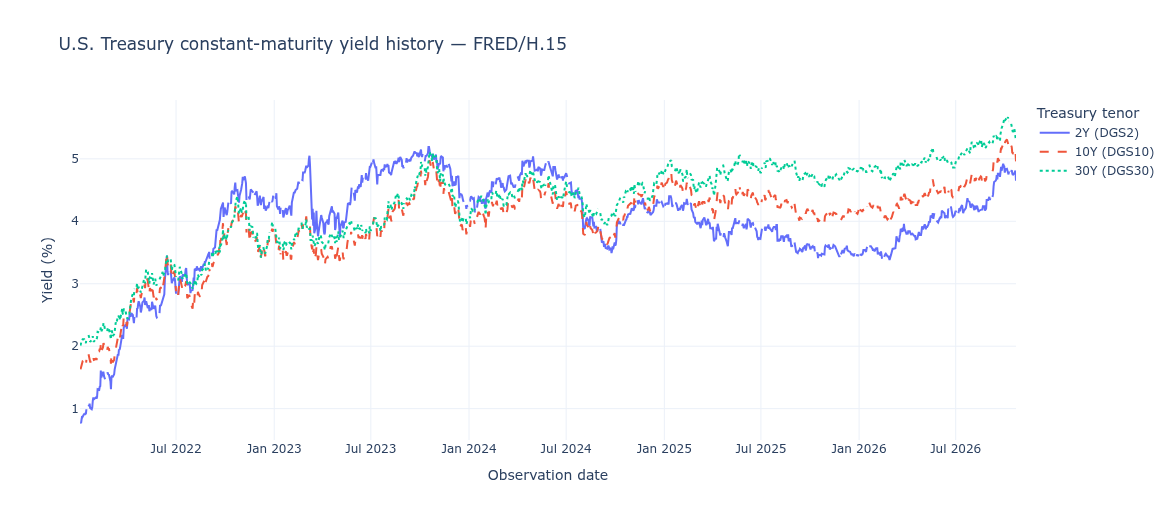

In [16]:
history_figure = show_yield_history(
    observations, *date_range.get_dates()
)

## C. Treasury Yield and Curve Movements

Calculate yield and spread changes between selected dates, classify curve movements, and display the results

In [18]:
result = analyze_curve(
    observations, *date_range.get_dates(),
    yield_change_tolerance_bp=5,
    slope_tolerance_bp=5,
)
show_curve_results(result)

,2022-01-03,End 2026-10-22,Change,Curve configuration,Movement / regime
Treasury measure,,,,,
2Y yield,0.78%,4.65%,+387.00 bp,—,Yield rose
10Y yield,1.63%,4.96%,+333.00 bp,—,Yield rose
30Y yield,2.01%,5.29%,+328.00 bp,—,Yield rose
10Y−2Y spread,+85.00 bp,+31.00 bp,-54.00 bp,Upward-sloping → Upward-sloping,Bear flattening
30Y−10Y spread,+38.00 bp,+33.00 bp,-5.00 bp,Upward-sloping → Upward-sloping,Yields rose; little slope change


Greatest upward yield movement among available tenors: 2Y (+387.00 bp). 10Y−2Y spread: Bear flattening. 30Y−10Y spread: Yields rose; little slope change. These are net endpoint movements, not the full path or a forecast. ETF rate-price effects depend on duration and other product characteristics.

In [19]:
result

,start,end,level_unit,change_bp,configuration_start,configuration_end,movement,slope,short_direction,long_direction
measure,,,,,,,,,,
DGS2,0.78,4.65,%,387.0,not_applicable,not_applicable,rose,not_applicable,not_applicable,not_applicable
DGS10,1.63,4.96,%,333.0,not_applicable,not_applicable,rose,not_applicable,not_applicable,not_applicable
DGS30,2.01,5.29,%,328.0,not_applicable,not_applicable,rose,not_applicable,not_applicable,not_applicable
DGS10_DGS2,85.00,31.00,bp,-54.0,upward,upward,bear,flattening,rose,rose
DGS30_DGS10,38.00,33.00,bp,-5.0,upward,upward,parallel_up,unchanged,rose,rose
